In [8]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
bilalabdulkadir1_baseball_path = kagglehub.dataset_download('bilalabdulkadir1/baseball')

print('Data source import complete.')


Using Colab cache for faster access to the 'baseball' dataset.
Data source import complete.


# Baseball Player Performance and Salary Analysis

## Project Overview
This project explores the relationship between baseball player performance statistics and salary levels. The analysis aims to identify key factors that influence player earnings and evaluate how performance metrics contribute to salary prediction.

## Objectives
- Explore and understand the dataset structure.
- Clean and prepare the data for analysis.
- Perform exploratory data analysis (EDA).
- Visualize relationships between performance metrics and salary.
- Build a regression model to predict player salaries.
- Evaluate model performance using statistical metrics.

## Dataset Description
The dataset contains baseball player performance statistics along with salary information. Variables may include:
- Player demographics
- Batting statistics
- Fielding statistics
- Career performance metrics
- Salary information

## Analysis Workflow
1. Data Loading
2. Data Cleaning
3. Exploratory Data Analysis
4. Feature Engineering
5. Regression Modeling
6. Model Evaluation
7. Conclusions and Insights

## Author
Bilal Abdulkadir Muhammed


In [9]:
# Import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)

print("Libraries loaded successfully.")


Libraries loaded successfully.


In [10]:
# Load dataset

import os

# View available files
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


/kaggle/input/baseball/multiple-regression.pdf
/kaggle/input/baseball/Baseball.xlsx


In [11]:
# Load dataset

import os

# View available files
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


/kaggle/input/baseball/multiple-regression.pdf
/kaggle/input/baseball/Baseball.xlsx


In [12]:
# Load dataset

import os

# View available files
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


/kaggle/input/baseball/multiple-regression.pdf
/kaggle/input/baseball/Baseball.xlsx


In [14]:
# Load Excel dataset

df = pd.read_excel(
    "/kaggle/input/baseball/Baseball.xlsx"
)

# Display first rows
df.head()

,Name,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
0,Alan Ashby,315,81,7,24,38,39,14,3449,835,69,321,414,375,N,W,632,43,10,475.0,N
1,Alvin Davis,479,130,18,66,72,76,3,1624,457,63,224,266,263,A,W,880,82,14,480.0,A
2,Andre Dawson,496,141,20,65,78,37,11,5628,1575,225,828,838,354,N,E,200,11,3,500.0,N
3,Andres Galarraga,321,87,10,39,42,30,2,396,101,12,48,46,33,N,E,805,40,4,91.5,N
4,Alfredo Griffin,594,169,4,74,51,35,11,4408,1133,19,501,336,194,A,W,282,421,25,750.0,A


In [15]:
# Dataset information

print("Shape:", df.shape)

df.info()


Shape: (263, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 263 entries, 0 to 262
Data columns (total 21 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Name       263 non-null    object 
 1   AtBat      263 non-null    int64  
 2   Hits       263 non-null    int64  
 3   HmRun      263 non-null    int64  
 4   Runs       263 non-null    int64  
 5   RBI        263 non-null    int64  
 6   Walks      263 non-null    int64  
 7   Years      263 non-null    int64  
 8   CAtBat     263 non-null    int64  
 9   CHits      263 non-null    int64  
 10  CHmRun     263 non-null    int64  
 11  CRuns      263 non-null    int64  
 12  CRBI       263 non-null    int64  
 13  CWalks     263 non-null    int64  
 14  League     263 non-null    object 
 15  Division   263 non-null    object 
 16  PutOuts    263 non-null    int64  
 17  Assists    263 non-null    int64  
 18  Errors     263 non-null    int64  
 19  Salary     263 non-null    float6

In [16]:
# First 5 rows
df.head()


,Name,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
0,Alan Ashby,315,81,7,24,38,39,14,3449,835,69,321,414,375,N,W,632,43,10,475.0,N
1,Alvin Davis,479,130,18,66,72,76,3,1624,457,63,224,266,263,A,W,880,82,14,480.0,A
2,Andre Dawson,496,141,20,65,78,37,11,5628,1575,225,828,838,354,N,E,200,11,3,500.0,N
3,Andres Galarraga,321,87,10,39,42,30,2,396,101,12,48,46,33,N,E,805,40,4,91.5,N
4,Alfredo Griffin,594,169,4,74,51,35,11,4408,1133,19,501,336,194,A,W,282,421,25,750.0,A


In [17]:
# Statistical summary
df.describe()


,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,PutOuts,Assists,Errors,Salary
count,263.000000,263.000000,263.000000,263.000000,263.000000,263.000000,263.000000,263.000000,263.000000,263.000000,263.000000,263.000000,263.000000,263.000000,263.000000,263.000000,263.000000
mean,403.642586,107.828897,11.619772,54.745247,51.486692,41.114068,7.311787,2657.543726,722.186312,69.239544,361.220532,330.418251,260.266160,290.711027,118.760456,8.593156,535.925882
std,147.307209,45.125326,8.757108,25.539816,25.882714,21.718056,4.793616,2286.582929,648.199644,82.197581,331.198571,323.367668,264.055868,279.934575,145.080577,6.606574,451.118681
min,19.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,19.000000,4.000000,0.000000,2.000000,3.000000,1.000000,0.000000,0.000000,0.000000,67.500000
25%,282.500000,71.500000,5.000000,33.500000,30.000000,23.000000,4.000000,842.500000,212.000000,15.000000,105.500000,95.000000,71.000000,113.500000,8.000000,3.000000,190.000000
50%,413.000000,103.000000,9.000000,52.000000,47.000000,37.000000,6.000000,1931.000000,516.000000,40.000000,250.000000,230.000000,174.000000,224.000000,45.000000,7.000000,425.000000
75%,526.000000,141.500000,18.000000,73.000000,71.000000,57.000000,10.000000,3890.500000,1054.000000,92.500000,497.500000,424.500000,328.500000,322.500000,192.000000,13.000000,750.000000
max,687.000000,238.000000,40.000000,130.000000,121.000000,105.000000,24.000000,14053.000000,4256.000000,548.000000,2165.000000,1659.000000,1566.000000,1377.000000,492.000000,32.000000,2460.000000


In [18]:
# Missing values
df.isnull().sum()


,0
Name,0
AtBat,0
Hits,0
HmRun,0
Runs,0
RBI,0
Walks,0
Years,0
CAtBat,0
CHits,0


In [19]:
df.columns.tolist()


['Name',
 'AtBat',
 'Hits',
 'HmRun',
 'Runs',
 'RBI',
 'Walks',
 'Years',
 'CAtBat',
 'CHits',
 'CHmRun',
 'CRuns',
 'CRBI',
 'CWalks',
 'League',
 'Division',
 'PutOuts',
 'Assists',
 'Errors',
 'Salary',
 'NewLeague']

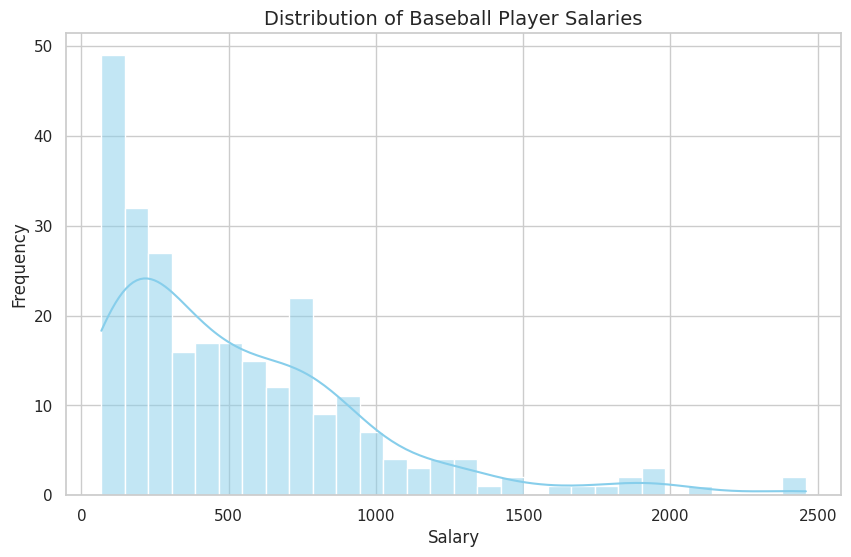

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the aesthetic style of the plots
sns.set_theme(style="whitegrid")

# Create a histogram of the Salary column
plt.figure(figsize=(10, 6))
sns.histplot(df['Salary'], bins=30, kde=True, color='skyblue')

plt.title('Distribution of Baseball Player Salaries', fontsize=14)
plt.xlabel('Salary', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

plt.show()

In [21]:
# Prepare data for regression

model_df = df.copy()

# Drop player name
model_df = model_df.drop('Name', axis=1)

# Convert categorical variables into dummy variables
model_df = pd.get_dummies(
    model_df,
    columns=['League', 'Division', 'NewLeague'],
    drop_first=True
)

model_df.head()


,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,PutOuts,Assists,Errors,Salary,League_N,Division_W,NewLeague_N
0,315,81,7,24,38,39,14,3449,835,69,321,414,375,632,43,10,475.0,True,True,True
1,479,130,18,66,72,76,3,1624,457,63,224,266,263,880,82,14,480.0,False,True,False
2,496,141,20,65,78,37,11,5628,1575,225,828,838,354,200,11,3,500.0,True,False,True
3,321,87,10,39,42,30,2,396,101,12,48,46,33,805,40,4,91.5,True,False,True
4,594,169,4,74,51,35,11,4408,1133,19,501,336,194,282,421,25,750.0,False,True,False


In [22]:
# Features and target

X = model_df.drop('Salary', axis=1)
y = model_df['Salary']

print("Features:", X.shape)
print("Target:", y.shape)


Features: (263, 19)
Target: (263,)


In [23]:
# Train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)


X_train: (210, 19)
X_test: (53, 19)


In [ ]:
# Train Linear Regression model

model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully!")


In [ ]:
# Predictions

y_pred = model.predict(X_test)

y_pred[:5]


In [28]:
# Ensure model is trained and evaluate
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R² :", round(r2, 4))

MAE : 211.12
RMSE: 358.17
R² : 0.2907


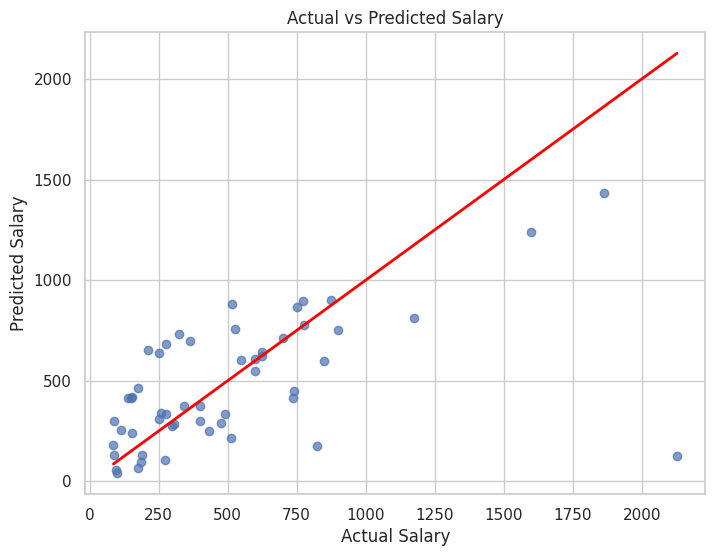

In [29]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred, alpha=0.7)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linewidth=2
)

plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Actual vs Predicted Salary")

plt.show()
